In [4]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print(os.getcwd())

/home/deploy/flight-trajectory-prediction


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import pandas as pd

from src import cleaning
from src import geo
from src import diagnostics

In [6]:
raw = cleaning.load_raw("paris")
with_pos = cleaning.remove_missing_positions(raw)
deduped = cleaning.remove_duplicates(with_pos)


print(len(raw))
print(len(with_pos))
print(len(deduped))

860656
860656
686903


In [7]:
deduped = deduped.sort_values(by=["icao24", "time_position"]).reset_index(drop=True)
deduped["gap_s"] = deduped.groupby("icao24")["time_position"].diff()

print(deduped["gap_s"].describe())

print("\nLargest gaps (seconds):")
print(deduped["gap_s"].sort_values(ascending=False).head(15))

count    681924.000000
mean       1590.291200
std       16485.851305
min           1.000000
25%          22.000000
50%          25.000000
75%          29.000000
max      610959.000000
Name: gap_s, dtype: float64

Largest gaps (seconds):
233171    610959.0
577114    609714.0
538434    605556.0
637880    603668.0
458598    596765.0
673916    596147.0
10998     596084.0
522996    588939.0
628534    580636.0
577967    580299.0
561791    577864.0
561750    575701.0
499957    575526.0
530357    574672.0
496268    573060.0
Name: gap_s, dtype: float64


In [8]:
COLUMNS = ["icao24", "callsign", "time_position", "gap_s",
           "latitude", "longitude", "geo_altitude", "on_ground", "vertical_rate"]

ambiguous = deduped[(deduped["gap_s"] > 300) & (deduped["gap_s"] < 3600)]
print(f"{len(ambiguous)} ambiguous gaps\n")
print()

for idx in ambiguous.index:
    print(f"gap of {deduped.loc[idx, 'gap_s'] / 60:.1f} min")
    print(deduped.loc[idx - 1 : idx, COLUMNS].to_string())
    print()

2834 ambiguous gaps


gap of 6.3 min
     icao24  callsign  time_position  gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
937  01028b               1795186084   14.0   49.0207     2.5570           NaN       True            NaN
938  01028b  MSR800       1795186465  381.0   49.0203     2.5076        525.78      False          14.96

gap of 8.8 min
      icao24  callsign  time_position  gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
1088  01028b               1795443118  123.0   49.0121     2.5460           NaN       True            NaN
1089  01028b  MSR800       1795443648  530.0   49.0181     2.5244           NaN       True            NaN

gap of 6.2 min
      icao24 callsign  time_position   gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
1229  01028b              1795617221  7082.0   49.0121     2.5454           NaN       True            NaN
1230  01028b              1795617591   370.0   49.0171     2.5229           NaN       

In [9]:
for threshold in [60, 300, 600, 900, 1200, 3600]:
    count = (deduped["gap_s"] > threshold).sum()
    print(f"gaps > {threshold / 60:>5.0f} min: {count}")

gaps >     1 min: 35369
gaps >     5 min: 22257
gaps >    10 min: 21377
gaps >    15 min: 21005
gaps >    20 min: 20809
gaps >    60 min: 19421


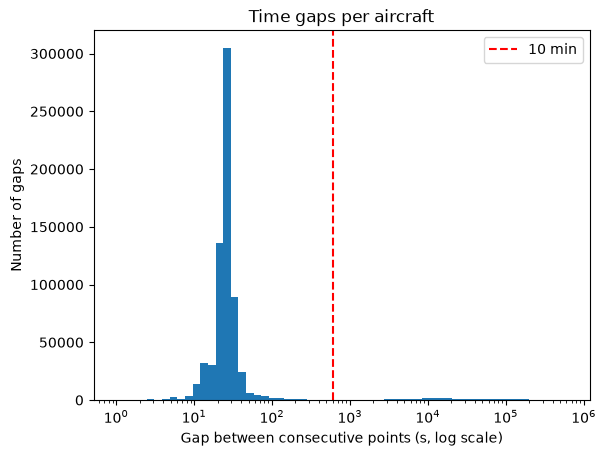

In [10]:
gaps = deduped["gap_s"].dropna()
bins = np.logspace(0, np.log10(gaps.max()), 60)

plt.hist(gaps, bins=bins)
plt.xscale("log")
plt.xlabel("Gap between consecutive points (s, log scale)")
plt.ylabel("Number of gaps")
plt.title("Time gaps per aircraft")
plt.axvline(600, color="red", linestyle="--", label="10 min")
plt.legend()
plt.show()

In [11]:
grouped_flights = cleaning.split_flights(deduped)

In [12]:
final_point = grouped_flights.groupby("flight_id").tail(1).copy()
final_point["distance_to_cdg_km"] = geo.haversine_km(final_point["latitude"], final_point["longitude"], geo.CDG_COORDS["lat"], geo.CDG_COORDS["lon"])

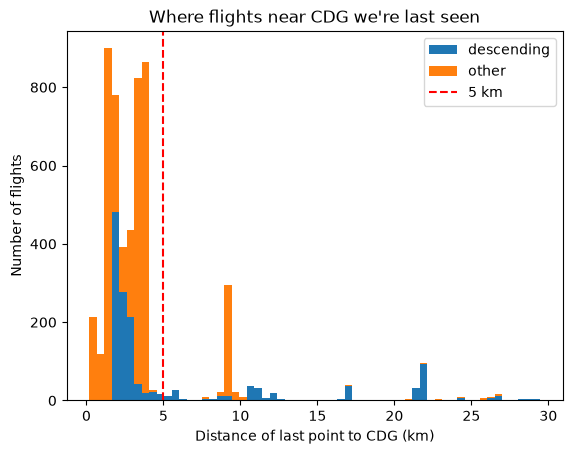

In [13]:
near = final_point[final_point["distance_to_cdg_km"] < 30]

descending = near[near["vertical_rate"] < 0]
other = near[~(near["vertical_rate"] < 0)]

plt.hist([descending["distance_to_cdg_km"], other["distance_to_cdg_km"]], bins=60, stacked=True, label=["descending", "other"])
plt.xlabel("Distance of last point to CDG (km)")
plt.ylabel("Number of flights")
plt.title("Where flights near CDG we're last seen")
plt.axvline(5, color="red", linestyle="--", label="5 km")
plt.legend()
plt.show()

In [14]:
MAX_DISTANCE_KM = 7
MAX_ALTITUDE_M = 500
MIN_AIRBORNE_ALT_M = 1000

airborne_flight_ids = grouped_flights[grouped_flights["geo_altitude"] > MIN_AIRBORNE_ALT_M]["flight_id"].unique()

is_close = final_point["distance_to_cdg_km"] < MAX_DISTANCE_KM
is_low = (final_point["on_ground"]) | (final_point["geo_altitude"] < MAX_ALTITUDE_M)
was_airborne = final_point["flight_id"].isin(airborne_flight_ids)

arrival_endpoints = final_point[is_close & is_low & was_airborne]
cdg_arrivals = grouped_flights[grouped_flights["flight_id"].isin(arrival_endpoints["flight_id"])]

n_flights = cdg_arrivals["flight_id"].nunique()
n_points = len(cdg_arrivals)

print(f"Flights checked: {len(final_point)}")
print(f"ending within {MAX_DISTANCE_KM} km: {is_close.sum()}")
print(f"and on ground/low: {(is_close & is_low).sum()}")
print(f"and were airborne: {len(arrival_endpoints)}")
print(f"Points in arrival tracks: {n_points} (~{n_points / n_flights:.0f} per flight)")

Flights checked: 26356
ending within 7 km: 4609
and on ground/low: 4594
and were airborne: 4309
Points in arrival tracks: 172343 (~40 per flight)


In [15]:
print(cleaning.keep_arrivals(grouped_flights, geo.CDG_COORDS)["flight_id"].nunique())

4309


In [16]:
grouped = cdg_arrivals.groupby("flight_id")

prev_lat = grouped["latitude"].shift()
prev_lon = grouped["longitude"].shift()

step_km = geo.haversine_km(
	prev_lat,
	prev_lon,
	cdg_arrivals["latitude"],
	cdg_arrivals["longitude"]
)

step_s = grouped["time_position"].diff()
implied_speed_kmh = step_km / (step_s / 3600)
vertical_speed_ms = grouped["geo_altitude"].diff() / step_s

print(f"Implied speed (km/h): {implied_speed_kmh.describe()}")
print(f"Vertical speed (m/s): {vertical_speed_ms.describe()}")

Implied speed (km/h): count    168034.000000
mean        388.006788
std         166.997720
min           0.000000
25%         280.966276
50%         409.288437
75%         507.966734
max        1642.793190
dtype: float64
Vertical speed (m/s): count    150714.000000
mean         -3.964507
std           3.455815
min         -38.100000
25%          -5.362222
50%          -4.103077
75%          -2.637692
max         864.108000
dtype: float64


In [17]:
inspect = cdg_arrivals.copy()
inspect["step_s"] = step_s
inspect["step_km"] = step_km
inspect["speed_kmh"] = implied_speed_kmh
inspect["vspeed_ms"] = vertical_speed_ms

COLS = ["flight_id", "time_position", "step_s", "step_km", "speed_kmh",
        "vspeed_ms", "latitude", "longitude", "geo_altitude", "on_ground"]

In [18]:
def show_with_neighbours(table, idx, cols=COLS):
    print(table.loc[idx - 1 : idx + 1, cols].to_string())
    print()

In [19]:
print("Top 5 highest speeds")
for idx in inspect["speed_kmh"].nlargest(5).index:
	show_with_neighbours(inspect, idx)
 
print("Points below -20 m/s")
for idx in inspect[inspect["vspeed_ms"] < -20].index:
    show_with_neighbours(inspect, idx)

climb_flight = inspect.loc[inspect["vspeed_ms"].idxmax(), "flight_id"]
one = inspect[inspect["flight_id"] == climb_flight]

print("Positive climb flight")
print(one)

Top 5 highest speeds
      flight_id  time_position  step_s    step_km    speed_kmh  vspeed_ms  latitude  longitude  geo_altitude  on_ground
56253  347308_1     1795222450    26.0  10.877170  1506.069699 -12.602308   48.9104     2.3537       3695.70      False
56254  347308_1     1795222475    25.0  11.408286  1642.793190 -14.020800   48.9169     2.5095       3345.18      False
56255  347308_1     1795222499    24.0  10.377418  1556.612644 -20.320000   48.9184     2.6515       2857.50      False

      flight_id  time_position  step_s    step_km    speed_kmh  vspeed_ms  latitude  longitude  geo_altitude  on_ground
56254  347308_1     1795222475    25.0  11.408286  1642.793190 -14.020800   48.9169     2.5095       3345.18      False
56255  347308_1     1795222499    24.0  10.377418  1556.612644 -20.320000   48.9184     2.6515       2857.50      False
56256  347308_1     1795222525    26.0  10.420780  1442.877242 -13.774615   48.9198     2.7941       2499.36      False

      flight_id  

In [20]:
median_flights_speed = inspect.groupby(by="flight_id")["speed_kmh"].median()
median_speed = median_flights_speed.median()

candidate_flight = median_flights_speed.sub(median_speed).abs().idxmin()

print(f"Median flight speed: {median_speed:.1f}")
print(candidate_flight)
median_flights_speed.sort_values(ascending=False).head(10)

Median flight speed: 419.7
3951c2_1


flight_id
347308_1    1057.233262
440d93_1     829.363151
440b2f_1     812.575890
392af8_1     775.095792
440051_5     750.780246
440ced_1     668.189479
440102_1     663.881406
a0996b_1     644.045632
39e68e_2     633.295444
40756b_1     633.115995
Name: speed_kmh, dtype: float64

In [21]:
flight_ids = ["347308_1", "440d93_1", "44a6e4_1", "398579_6"]

for flight_id in flight_ids:
    print(f"Flight: {flight_id}")
    print(inspect.loc[inspect["flight_id"] == flight_id, ["time_position", "speed_kmh", "callsign"]].assign(
		velocity_kmh=inspect["velocity"] * 3.6,
		ratio=inspect["speed_kmh"] / (inspect["velocity"] * 3.6)
	))

Flight: 347308_1
       time_position    speed_kmh  callsign  velocity_kmh     ratio
56249     1795222349          NaN  SWT5614        644.400       NaN
56250     1795222373  1499.634694  SWT5614        628.632  2.385553
56251     1795222397  1530.280688  SWT5614        587.700  2.603847
56252     1795222424  1412.912294  SWT5614        594.756  2.375617
56253     1795222450  1506.069699  SWT5614        587.196  2.564850
56254     1795222475  1642.793190  SWT5614        587.124  2.798034
56255     1795222499  1556.612644  SWT5614        585.288  2.659567
56256     1795222525  1442.877242  SWT5614        546.372  2.640833
56257     1795222540  1382.012610  SWT5614        538.992  2.564069
56258     1795222573  1043.874397  SWT5614        424.836  2.457123
56259     1795222599  1057.233262  SWT5614        400.752  2.638123
56260     1795222627   981.706897  SWT5614        299.160  3.281545
56261     1795222648   806.713698  SWT5614        269.316  2.995417
56262     1795222677   696.9287

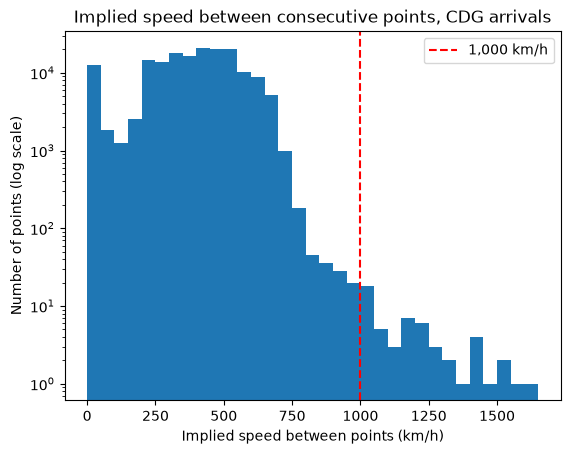

In [22]:
speeds = implied_speed_kmh.dropna()
bins = np.arange(0, speeds.max() + 50, 50)

plt.hist(speeds, bins=bins)
plt.yscale("log")
plt.xlabel("Implied speed between points (km/h)")
plt.ylabel("Number of points (log scale)")
plt.title("Implied speed between consecutive points, CDG arrivals")
plt.axvline(1000, color="red", linestyle="--", label="1,000 km/h")
plt.legend()
plt.show()

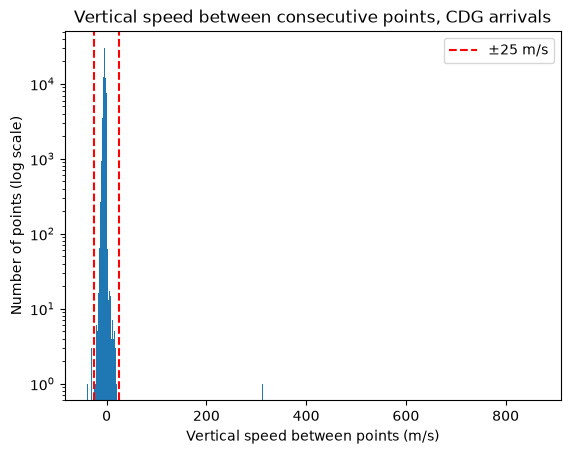

In [23]:
vertical = vertical_speed_ms.dropna()
vertical_bins = np.arange(np.floor(vertical.min()), np.ceil(vertical.max()) + 1, 1)

plt.hist(vertical, bins=vertical_bins)
plt.yscale("log")
plt.xlabel("Vertical speed between points (m/s)")
plt.ylabel("Number of points (log scale)")
plt.title("Vertical speed between consecutive points, CDG arrivals")
plt.axvline(-25, color="red", linestyle="--", label="±25 m/s")
plt.axvline(25, color="red", linestyle="--")
plt.legend()
plt.show()

0.48054991116760665


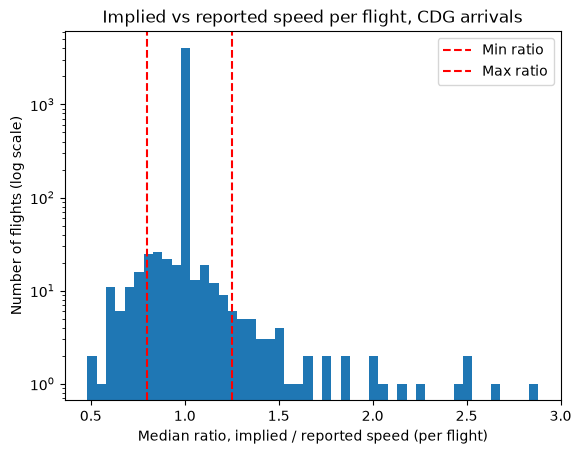

In [24]:
inspect["velocity_kmh"] = inspect["velocity"] * 3.6
inspect["ratio"] = inspect["speed_kmh"] / inspect["velocity_kmh"]

medians = inspect[inspect["velocity_kmh"] >= 50].groupby("flight_id")["ratio"].median().dropna()
median_bins = np.arange(medians.min(), medians.max() + 0.05, 0.05)

print(medians.min())

plt.hist(medians, bins=median_bins)
plt.yscale("log")
plt.axvline(0.8, color="red", linestyle="--", label="Min ratio")
plt.axvline(1.25, color="red", linestyle="--", label="Max ratio")
plt.title("Implied vs reported speed per flight, CDG arrivals")
plt.ylabel("Number of flights (log scale)")
plt.xlabel("Median ratio, implied / reported speed (per flight)")
plt.legend()
plt.show()

In [25]:
cols = ["speed_kmh", "velocity_kmh", "ratio", "step_s"]
lowest_ratio_flight = medians.idxmin()
flight_rows = inspect[inspect["flight_id"] == lowest_ratio_flight]

print(flight_rows[cols + ["flight_id"]])

fig = px.line_map(
    data_frame=flight_rows,
    lat="latitude",
    lon="longitude",
    center={"lat": 48.86, "lon": 2.35},
    zoom=8,
	hover_data=cols + ["geo_altitude"],
	map_style="carto-positron"
)

fig.show()

         speed_kmh  velocity_kmh     ratio  step_s flight_id
132956         NaN       413.964       NaN     NaN  392af5_1
132957  201.040742       416.664  0.482501     9.0  392af5_1
132958  223.740835       425.700  0.525583    38.0  392af5_1
132959  202.385424       427.320  0.473616    17.0  392af5_1
132960  218.181123       422.208  0.516762    34.0  392af5_1
132961  192.861061       414.360  0.465443    27.0  392af5_1
132962  191.799724       407.628  0.470526    22.0  392af5_1
132963  184.455469       398.412  0.462977    28.0  392af5_1
132964  166.237848       394.560  0.421325    15.0  392af5_1
132965  176.635383       381.672  0.462794    33.0  392af5_1
132966  187.789610       377.352  0.497651    20.0  392af5_1
132967  169.060452       374.220  0.451768    29.0  392af5_1
132968  176.711914       376.056  0.469909    27.0  392af5_1
132969  222.035395       377.712  0.587843    11.0  392af5_1
132970  186.860947       382.464  0.488571    36.0  392af5_1
132971  171.799911      

In [26]:
low_ratio_flight = inspect[inspect["flight_id"] == "392af5_2"].copy()

snap_step_s = low_ratio_flight["snapshot_time"].diff()
snap_implied_speed_kmh = low_ratio_flight["step_km"] / (snap_step_s.dt.total_seconds() / 3600)

low_ratio_flight["snap_ratio"] = snap_implied_speed_kmh / low_ratio_flight["velocity_kmh"]

print(f"ratio using 'time_position': {low_ratio_flight["ratio"].median()}")
print(f"ratio using 'snapshot_time': {low_ratio_flight["snap_ratio"].median()}")

ratio using 'time_position': nan
ratio using 'snapshot_time': nan


In [27]:
high_ratio_flight = inspect[inspect["flight_id"] == "347308_1"].copy()
ratio = diagnostics.speed_ratio(high_ratio_flight, "snapshot_time")

print(f"ratio using 'time_position': {high_ratio_flight["ratio"].median()}")
print(f"ratio using 'snapshot_time': {ratio.median()}")

ratio using 'time_position': 2.603846670285787
ratio using 'snapshot_time': 2.6158028596208354


In [28]:
cdg_arrivals_ratio = diagnostics.speed_ratio(cdg_arrivals)
ratio_medians = cdg_arrivals_ratio.groupby(cdg_arrivals["flight_id"]).median()

ranges = [(0.9, 1.1), (0.8, 1.25), (0.75, 1.33)]

for low, high in ranges:
	outside = (ratio_medians < low) | (ratio_medians > high)
	print(f"Outside {low}-{high}: {outside.sum()} flights ({outside.mean() * 100:.1f}%)")

Outside 0.9-1.1: 182 flights (4.2%)
Outside 0.8-1.25: 100 flights (2.3%)
Outside 0.75-1.33: 69 flights (1.6%)


In [29]:
borderline = ratio_medians[ratio_medians.between(0.75, 0.8) | ratio_medians.between(1.25, 1.33)]

for flight_id in borderline.sample(4).index:
    rows = cdg_arrivals[cdg_arrivals["flight_id"] == flight_id]
    ratio = diagnostics.speed_ratio(rows)
    
    print(f"Flight {flight_id} ({rows["callsign"].iloc[0]}), median ratio {ratio.median():.2f}")
    print(pd.DataFrame({
		"velocity_kmh": rows["velocity"] * 3.6,
		"ratio": ratio
	}).to_string())

Flight 0201c2_1 (RAM788H ), median ratio 0.80
      velocity_kmh     ratio
9646       622.044       NaN
9647       622.044  0.941028
9648       626.184  0.874299
9649       624.528  0.870785
9650       618.732  0.895981
9651       618.732  0.793673
9652       644.760  0.817042
9653       658.908  0.805605
9654       665.172  0.849369
9655       622.908  0.891987
9656       617.364  0.799219
9657       617.220  0.868102
9658       613.188  0.818120
9659       609.660  0.893186
9660       609.660  0.860391
9661       611.352  0.824117
9662       612.756  0.811746
9663       614.988  0.770236
9664       592.740  0.857610
9665       576.072  0.782920
9666       566.784  0.765901
9667       557.568  0.814740
9668       553.824  0.870905
9669       550.080  0.772552
9670       542.700  0.824074
9671       544.536  0.800118
9672       544.536  0.837821
9673       542.664  0.697106
9674       537.120  0.816274
9675       535.320  0.801988
9676       531.648  0.725683
9677       533.412  0.7878

In [30]:
print(cdg_arrivals["flight_id"].nunique())
plausible_flights = cleaning.remove_implausible_flights(cdg_arrivals)
print(plausible_flights["flight_id"].nunique())

4309
4209


In [31]:
show_with_neighbours(inspect, inspect["vspeed_ms"].idxmax(), ['geo_altitude', 'step_s', 'flight_id'])

        geo_altitude  step_s flight_id
307349        274.32    18.0  39d2ab_7
307350       4594.86     5.0  39d2ab_7
307351           NaN   118.0  39d2ab_7



In [32]:
print(plausible_flights[plausible_flights["flight_id"] == "39d2ab_7"])

       icao24  callsign origin_country  time_position  last_contact  \
84285  39d2ab  AFR199           France     1795627539    1795627539   
84286  39d2ab  AFR199           France     1795627567    1795627568   
84287  39d2ab  AFR199           France     1795627595    1795627595   
84288  39d2ab  AFR199           France     1795627619    1795627619   
84289  39d2ab  AFR199           France     1795627642    1795627642   
84290  39d2ab  AFR199           France     1795627667    1795627668   
84291  39d2ab  AFR199           France     1795627695    1795627695   
84292  39d2ab  AFR199           France     1795627716    1795627716   
84293  39d2ab  AFR199           France     1795627729    1795627729   
84294  39d2ab  AFR199           France     1795627769    1795627769   
84295  39d2ab  AFR199           France     1795627792    1795627793   
84296  39d2ab  AFR199           France     1795627819    1795627819   
84297  39d2ab  AFR199           France     1795627840    1795627840   
84298 

In [38]:
plausible_altitude_flights = cleaning.fix_altitude_spikes(plausible_flights)
afr199 = plausible_altitude_flights[plausible_altitude_flights["flight_id"] == "39d2ab_7"]
print(afr199[["time_position", "geo_altitude", "on_ground"]].tail(5))

       time_position  geo_altitude  on_ground
84330     1795628671        335.28      False
84331     1795628689        274.32      False
84332     1795628694           NaN      False
84333     1795628812           NaN       True
84334     1795628820           NaN       True
